# Selection on structural variants — main figures

The two headline results:

1. **Figure 1** — SVs, insertions particularly, carry the classic site-frequency signature of
   purifying selection in the 231-founder panel: shifted towards rare relative to synonymous SNPs,
   more negative Tajima's *D*, and depleted from coding sequence relative to genomic expectation.
2. **Figure 2** — the same signal acting in real time: in GrENE-Net, insertions (and, in CDS,
   deletions moving the other way) shift in frequency relative to matched same-context SNPs across
   the 31 gardens.

**Unit and filters** (as in `sv_main_fig1.ipynb`/`sv_main_fig2.ipynb`): the SV **event** (arch3
alleles of a pangenome bubble merged with `truvari collapse` defaults); called in ≥ 90% of the 231
founders throughout; ≥ 2 carrier founders for the GrENE-Net panel, singletons included in the
spectra. Context, first match wins: CDS > UTR > intron > reference TE > promoter (≤ 2 kb upstream)
> intergenic.

The last section re-expresses result 2 as a site-frequency spectrum (seed mix → final generation), which
is where the drift baseline and the limits of the CDS-specific claim are easiest to see.

**Otherwise this notebook is just the two main-text figures.** Full per-context panels, robustness checks, the
origin/climate walk-through, and every supplement are in `sv_main_fig1.ipynb` and
`sv_main_fig2.ipynb`; Figure 3 (which SVs are being purified) is in `sv_main_fig3.ipynb`.

In [1]:

import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from matplotlib.ticker import PercentFormatter
plt.rcParams.update({'figure.dpi':120,'font.size':8,'axes.linewidth':0.6,'savefig.bbox':'tight'})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive"))
CTX=["CDS","UTR","intron","TE","promoter","intergenic"]
KC={"snp":"0.15","indel":"0.62","ins":"#D95F02","del":"#1B9E77"}; KL={"snp":"SNPs","indel":"short indels","ins":"insertions","del":"deletions"}
OC={"cold-specific":"#2166AC","shared":"0.45","warm-specific":"#B2182B"}
def style(ax,axis="both"):
    ax.set_axisbelow(True); ax.grid(color="0.9",lw=0.6,axis=axis)
    for sp in ax.spines.values(): sp.set_visible(False)
def panel(ax,letter): ax.annotate(letter,xy=(-0.12,1.04),xycoords="axes fraction",fontsize=11,fontweight="bold")
rng=np.random.default_rng(0)
D=pd.read_csv(f"{G}/sv_event_catalog.csv"); PALL=np.load(f"{G}/sv_event_catalog_p_poolaf.npy")   # kMate pool allele frequencies (seed mix + each garden)
ok=D.passes.to_numpy(); E=D[ok].reset_index(drop=True); PE=PALL[ok]
CS=np.load(f"{G}/classic_sfs.npz"); M=int(CS["M"])
def maf(name): c=CS[f"{name}_c"].astype(float); k=CS[f"{name}_k"].astype(float); f=c/k; return np.minimum(f,1-f)
def tajD(names):
    # Tajima's D of a class, directly from its variants (no projection): per variant, c carriers among k called founders
    names=[names] if isinstance(names,str) else names
    c=np.concatenate([CS[f"{n}_c"] for n in names]).astype(float); k=np.concatenate([CS[f"{n}_k"] for n in names]).astype(float)
    h=2*c*(k-c)/(k*(k-1)); n=int(np.median(k)); j=np.arange(1,n); a1=(1/j).sum(); a2=(1/j**2).sum()
    b1=(n+1)/(3*(n-1)); b2=2*(n*n+n+3)/(9*n*(n-1)); c1=b1-1/a1; c2=b2-(n+2)/(a1*n)+a2/a1**2; e1=c1/a1; e2=c2/(a1**2+a2)
    D=lambda hh:(hh.sum()-hh.size/a1)/np.sqrt(e1*hh.size+e2*hh.size*(hh.size-1))
    return D(h),h,D
def tajD_matched(snp_name,sv_name,per=50,seed=0):
    # Tajima's D of SNPs re-weighted to the SV class's call-rate distribution: for every value of k (called founders) among the
    # SV events, draw up to per x (number of events with that k) SNPs with exactly that k. Bootstrap CI over the drawn SNPs.
    r=np.random.default_rng(seed); cs=CS[f"{snp_name}_c"].astype(int); ks=CS[f"{snp_name}_k"].astype(int); kv=CS[f"{sv_name}_k"].astype(int)
    pick=[]
    for kk,n in zip(*np.unique(kv,return_counts=True)):
        pool=np.where(ks==kk)[0]
        if pool.size: pick.append(r.choice(pool,min(per*n,pool.size),replace=False))
    pick=np.concatenate(pick); c=cs[pick].astype(float); k=ks[pick].astype(float)
    h=2*c*(k-c)/(k*(k-1)); n=int(np.median(k)); j=np.arange(1,n); a1=(1/j).sum(); a2=(1/j**2).sum()
    b1=(n+1)/(3*(n-1)); b2=2*(n*n+n+3)/(9*n*(n-1)); c1=b1-1/a1; c2=b2-(n+2)/(a1*n)+a2/a1**2; e1=c1/a1; e2=c2/(a1**2+a2)
    D=lambda hh:(hh.sum()-hh.size/a1)/np.sqrt(e1*hh.size+e2*hh.size*(hh.size-1)); bs=[D(r.choice(h,h.size)) for _ in range(100)]
    return D(h),np.percentile(bs,2.5),np.percentile(bs,97.5)
def tajD_ci(names,B=300):
    d,h,D=tajD(names)
    if h.size>20000:                                  # large SNP classes: CI is negligible, fewer draws
        bs=[D(rng.choice(h,h.size)) for _ in range(40)]
    else: bs=[D(rng.choice(h,h.size)) for _ in range(B)]
    return d,np.percentile(bs,2.5),np.percentile(bs,97.5)
print(f"events passing: {len(E):,} ({(E.kind=='ins').sum():,} insertions, {(E.kind=='del').sum():,} deletions)")
# robustness checks (`_sv_main_figures_checks.py`): matched-SNP-set null for the load statistic, founder
# origin in the burden model, spectra without singletons
CKM=pd.read_csv(f"{G}/main_fig_checks_lmm.csv").set_index("check")
CKS=pd.read_csv(f"{G}/main_fig_checks_nosingleton.csv")
pfmt=lambda p: "p < 0.001" if p<=0.001 else f"p = {p:.2g}"


events passing: 18,418 (12,981 insertions, 5,437 deletions)


## Figure 1 — Purifying selection on SVs in the founders

**(a)** Folded site-frequency spectra as cumulative distributions of minor-allele frequency, for
insertions and deletions in coding sequence (left) and in introns (right), against the neutral
reference (synonymous SNPs, dashed grey) and the known-selected comparator (nonsynonymous SNPs, black).
A curve above the neutral one = a class shifted towards rare variants, the footprint of purifying
selection. Two-sample Kolmogorov–Smirnov *D* against synonymous SNPs in each panel.
**(b)** Tajima's *D* per genomic context: insertions and deletions against SNPs of the same context
(95% bootstrap CI); more negative = shifted towards rare variants. Because Tajima's *D* in this panel
depends on how many founders a variant is called in (complete calls select simple pangenome bubbles,
which are enriched for rare variants), the SNP reference for each class (black; filled for insertions,
open for deletions) is drawn to the class's own distribution of called founders. The synonymous /
nonsynonymous anchor for the size of a selective shift is in (a). **(c)** Where each class is found:
share of the class in each context divided by the context's share of genomic length (1 = uniform
placement), insertions and deletions against SNPs.

*Statistics.* Folded MAF per variant = min(c/k, 1 − c/k), c carriers among k called founders
(k ≥ 208 of 231, 1 ≤ c ≤ k − 1; singletons included). Tajima's *D* per class from the variants' allele counts
(Tajima 1989; identical to scikit-allel on complete data; missing calls handled per site), bootstrap CI
over variants; SNP references in (b) drawn to the SV class's call-rate distribution (up to 50 SNPs per
event with exactly the same number of called founders); synonymous / nonsynonymous calls from the reference codon and the codon carrying the
ALT base (representative gene model).

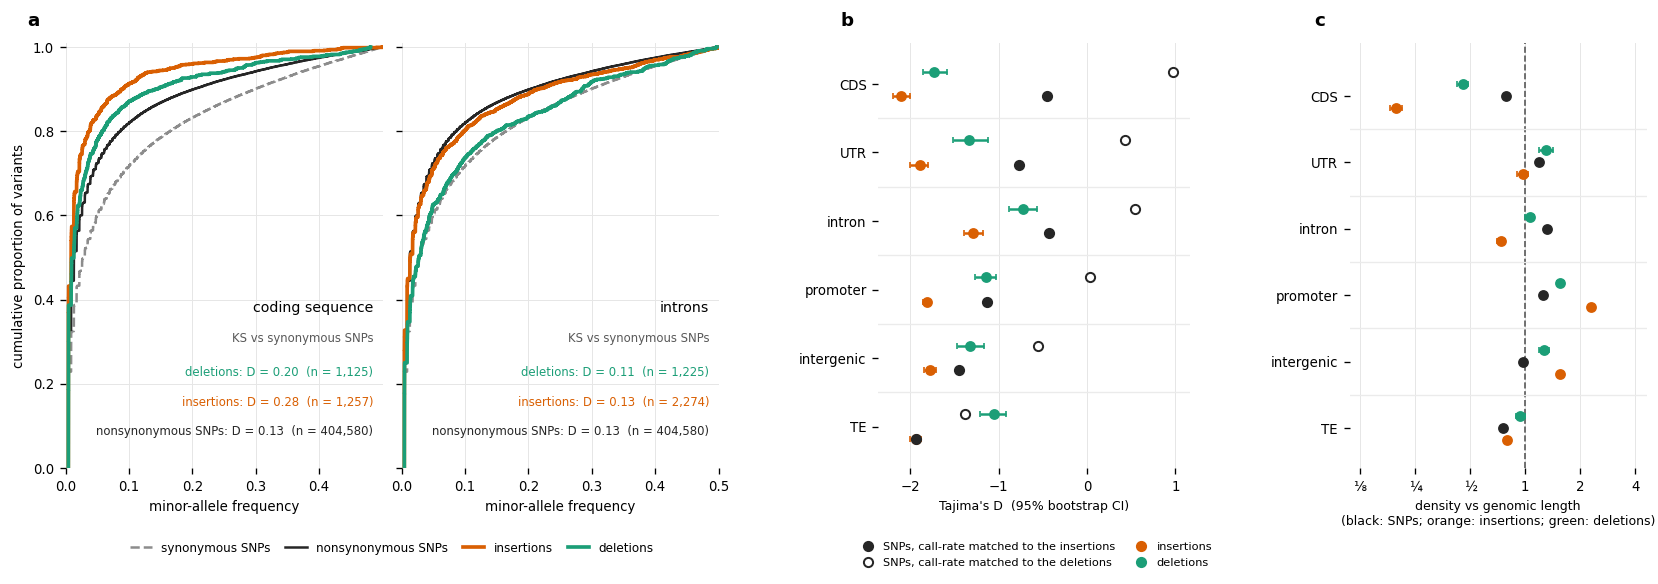

Figure 1a  cumulative spectra; KS vs synonymous SNPs:
context                cls      n  maf_lt1  maf_lt5  maf_lt10  KS_D  KS_p
    CDS    synonymous SNPs 394676    0.325    0.599     0.716 0.000   1.0
    CDS nonsynonymous SNPs 404580    0.445    0.724     0.819 0.132   0.0
    CDS         insertions   1257    0.574    0.837     0.912 0.277   0.0
    CDS          deletions   1125    0.499    0.778     0.870 0.197   0.0
 intron    synonymous SNPs 394676    0.325    0.599     0.716 0.000   1.0
 intron nonsynonymous SNPs 404580    0.445    0.724     0.819 0.132   0.0
 intron         insertions   2274    0.450    0.709     0.802 0.128   0.0
 intron          deletions   1225    0.347    0.625     0.736 0.111   0.0

neutral reference check — synonymous / nonsynonymous vs the stricter 4-fold / 0-fold sites:
       cls      n  maf_lt5   TajD
   snp_syn 394676    0.599 -0.623
 snp_4fold 227958    0.596 -0.597
snp_nonsyn 404580    0.724 -1.394
 snp_0fold 345663    0.729 -1.425

Figure 1b  Tajim

In [2]:

REF=maf("snp_syn")
def ecdf(a,v,**k):
    v=np.sort(v); a.step(np.r_[v[0],v],np.r_[0,np.arange(1,v.size+1)/v.size],where="post",**k)
fig=plt.figure(figsize=(17,4.6)); gs_=fig.add_gridspec(1,3,width_ratios=[2.2,1.05,1],wspace=0.38)
GSH=pd.read_csv(f"{G}/context_genome_share.csv").set_index("context").share.reindex(CTX).to_numpy()
S=np.load(f"{G}/sv_sfs_context_origin_event.npz"); m=S["snp_n"]>=2; ns=np.bincount(S["snp_ctx"][m],minlength=6); snp_sh=ns/ns.sum(); rs=snp_sh/GSH
TD={name:tajD_ci(name) for name in ["snp_syn","snp_nonsyn","snp_4fold","snp_0fold"]+[f"{k}_{x}" for k in ("snp","ins","del") for x in CTX]}
order=["TE","intergenic","promoter","intron","UTR","CDS"]; order_c=order                # same fixed order in (b) and (c): CDS at the bottom
OFF={"ins":-0.18,"del":0.18}; SF=[]; DENS={}
# (a) folded SFS as cumulative distributions: insertions and deletions together, coding sequence and introns apart
gsa=gs_[0,0].subgridspec(1,2,wspace=0.06); a1=fig.add_subplot(gsa[0,0]); a2=fig.add_subplot(gsa[0,1],sharey=a1)
for a,x,ttl in ((a1,"CDS","coding sequence"),(a2,"intron","introns")):
    style(a); txt=[]
    for name,lab,col,ls,lw in (("snp_syn","synonymous SNPs","0.55","--",1.5),("snp_nonsyn","nonsynonymous SNPs","0.15","-",1.5),(f"ins_{x}","insertions",KC["ins"],"-",2.2),(f"del_{x}","deletions",KC["del"],"-",2.2)):
        v=maf(name); ks=stats.ks_2samp(v,REF); ecdf(a,v,color=col,ls=ls,lw=lw,label=lab)
        if name!="snp_syn": txt.append((f"{lab}: D = {ks.statistic:.2f}  (n = {v.size:,})",col))
        SF.append(dict(context=x,cls=lab,n=v.size,maf_lt1=(v<0.01).mean(),maf_lt5=(v<0.05).mean(),maf_lt10=(v<0.10).mean(),KS_D=ks.statistic,KS_p=ks.pvalue))
    a.set_xlim(0,0.5); a.set_ylim(0,1.01); a.set_xlabel("minor-allele frequency"); a.set_xticks([0,0.1,0.2,0.3,0.4]+([0.5] if x=="intron" else []))
    a.annotate(ttl,xy=(0.97,0.36),xycoords="axes fraction",ha="right",va="bottom",fontsize=8.5)
    a.annotate("KS vs synonymous SNPs",xy=(0.97,0.29),xycoords="axes fraction",ha="right",va="bottom",fontsize=7,color="0.35")
    for q,(s_,col) in enumerate(txt[::-1]): a.annotate(s_,xy=(0.97,0.21-0.07*q),xycoords="axes fraction",ha="right",va="bottom",fontsize=7,color=col)
a1.set_ylabel("cumulative proportion of variants"); a2.tick_params(labelleft=False); panel(a1,"a")
h_,l_=a1.get_legend_handles_labels(); a1.legend(h_,l_,frameon=False,fontsize=7.2,loc="upper center",bbox_to_anchor=(1.03,-0.15),ncol=4,columnspacing=1.2,handlelength=1.8)
# (b) Tajima's D per context: insertions and deletions against SNPs of the same context drawn to the same call-rate distribution
a=fig.add_subplot(gs_[0,1]); style(a,axis="x"); panel(a,"b"); DD_={}; TM={}
for i,x in enumerate(order):
    for k in ("ins","del"):
        y=i+OFF[k]; v_=TD[f"{k}_{x}"]; m_=tajD_matched(f"snp_{x}",f"{k}_{x}"); TM[(k,x)]=m_; DD_[(k,x)]=(v_[0]-m_[0],v_[1]-m_[0],v_[2]-m_[0])
        a.errorbar(m_[0],y,xerr=[[m_[0]-m_[1]],[m_[2]-m_[0]]],fmt="o",color=KC["snp"],mfc="white" if k=="del" else KC["snp"],mew=1.2,ms=5.5,capsize=2,zorder=4)
        a.errorbar(v_[0],y,xerr=[[v_[0]-v_[1]],[v_[2]-v_[0]]],fmt="o",color=KC[k],ms=5.5,capsize=2,zorder=3)
    if i<len(order)-1: a.axhline(i+0.5,color="0.92",lw=0.8)
a.set_yticks(range(len(order))); a.set_yticklabels(order); a.set_ylim(-0.6,len(order)-0.4)
for k,lab,fc in (("snp","SNPs, call-rate matched to the insertions",KC["snp"]),("snp","SNPs, call-rate matched to the deletions","white"),("ins","insertions",KC["ins"]),("del","deletions",KC["del"])):
    a.errorbar([],[],fmt="o",color=KC[k],mfc=fc,mew=1.2,ms=5.5,label=lab)
a.legend(frameon=False,fontsize=6.8,loc="upper center",bbox_to_anchor=(0.5,-0.15),ncol=2,columnspacing=1.2,handletextpad=0.4)
a.set_xlabel("Tajima's D  (95% bootstrap CI)",fontsize=7.5)
gap=TD["snp_nonsyn"][0]-TD["snp_syn"][0]
# (c) where they are found: share in context / share of genomic length
a=fig.add_subplot(gs_[0,2]); style(a,axis="x"); panel(a,"c"); a.axvline(1,color="0.35",lw=1,ls="--")
for k in ("ins","del"):
    nk=E[E.kind==k].context.value_counts().reindex(CTX).to_numpy(); sh=nk/nk.sum(); rk=sh/GSH; DENS[KL[k]]=rk
    for j,x in enumerate(order_c):
        i=CTX.index(x); y=j+OFF[k]
        a.errorbar(rk[i],y,xerr=1.96*np.sqrt(sh[i]*(1-sh[i])/nk.sum())/GSH[i],fmt="o",color=KC[k],ms=5.5,capsize=2,zorder=3)
for j,x in enumerate(order_c):
    i=CTX.index(x); a.errorbar(rs[i],j,xerr=1.96*np.sqrt(snp_sh[i]*(1-snp_sh[i])/ns.sum())/GSH[i],fmt="o",color=KC["snp"],ms=5.5,capsize=2,zorder=4)
    if j<5: a.axhline(j+0.5,color="0.92",lw=0.8)
a.set_xscale("log",base=2); a.set_xticks([0.125,0.25,0.5,1,2,4]); a.set_xticklabels(["⅛","¼","½","1","2","4"]); a.set_xlim(0.11,4.6)
a.set_yticks(range(6)); a.set_yticklabels(order_c); a.set_ylim(-0.6,5.8); a.set_xlabel("density vs genomic length\n(black: SNPs; orange: insertions; green: deletions)",fontsize=7.5)
fig.savefig(f"{G}/plots/main_fig1.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{G}/plots/main_fig1.pdf",bbox_inches="tight"); plt.show()
print("Figure 1a  cumulative spectra; KS vs synonymous SNPs:"); print(pd.DataFrame(SF).drop_duplicates(["context","cls"]).round(3).to_string(index=False))
print("\nneutral reference check — synonymous / nonsynonymous vs the stricter 4-fold / 0-fold sites:")
print(pd.DataFrame([dict(cls=n_,n=maf(n_).size,maf_lt5=(maf(n_)<0.05).mean(),TajD=TD[n_][0]) for n_ in ("snp_syn","snp_4fold","snp_nonsyn","snp_0fold")]).round(3).to_string(index=False))
print("\nFigure 1b  Tajima's D [95% CI]:"); print(pd.DataFrame({k_:dict(D=v[0],lo=v[1],hi=v[2]) for k_,v in TD.items()}).T.round(2).to_string())
print(f"\nFigure 1b  Tajima's D: SV class, SNPs of the context (all), SNPs call-rate matched to the class, and the class minus the matched SNPs [95% CI]; for scale, nonsynonymous - synonymous SNPs = {gap:+.2f}")
print(pd.DataFrame({f"{KL[k]} {x}":dict(D_class=TD[f"{k}_{x}"][0],D_snps_all=TD[f"snp_{x}"][0],D_snps_matched=TM[(k,x)][0],dD_matched=v[0],lo=v[1],hi=v[2]) for (k,x),v in DD_.items()}).T.round(2).to_string())
print("\nFigure 1c  share / genomic share:"); print(pd.DataFrame(dict(genome=GSH,SNPs=rs,**DENS),index=CTX).round(2).to_string())
# reading frame (not drawn): share of events whose length is a multiple of 3 (1/3 expected outside coding sequence)
I=E[E.kind=="ins"]; C=I[I.context=="CDS"]; rows=[]
for lab,d in (("CDS insertions, gene duplicate",C[C.seq_class=="gene_dup"]),("CDS insertions, TE-derived",C[C.seq_class=="te_derived"]),("all CDS insertions",C),
              ("CDS deletions",E[(E.kind=="del")&(E.context=="CDS")]),("insertions, other contexts",I[I.context!="CDS"])):
    x_=int((d.size_bp%3==0).sum()); n=len(d); ci=stats.binomtest(x_,n,1/3).proportion_ci(); rows.append(dict(group=lab,n=n,in_frame=x_/n,lo=ci.low,hi=ci.high))
print("\nreading frame (not drawn):"); print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nrobustness — with singletons (1) and without (minor-allele count >= 2): share MAF < 5%, KS D vs synonymous SNPs")
print(CKS.pivot(index="cls",columns="min_minor_count",values=["maf_lt5","KS_D"]).reindex(["snp_syn","snp_nonsyn","ins_CDS","ins_UTR","ins_intron","ins_TE","ins_promoter","ins_intergenic","del_CDS"]).round(3).to_string())


In [3]:

GS=np.load(f"{G}/garden_af_event.npz"); PV=GS["p"].astype(np.float64); KD=GS["kind"].astype(str); CX=GS["ctx"]; ZN=GS["zone"].astype(str); ORG=GS["origin"].astype(str); BIO=GS["bio1"]
NCAR=GS["n"].astype(int); BQ=np.quantile(GS["b1"][KD=="snp"],[0.2,0.4,0.6,0.8]); QCL=np.digitize(GS["b1"],BQ)          # carrier-climate quintile (edges from SNPs)
CB=np.array([2,3,4,5,6,8,11,16,26,51,1000])
CELLX=NCAR*10+QCL                                   # exact match: same number of carrier founders x same carrier-climate quintile
CELLB=np.digitize(NCAR,CB)*10+QCL                   # fallback: carrier-count bin x quintile, used only when the exact cell holds no SNP
SH=(GS["nc"]>0)&(GS["nw"]>0); zc=np.where(ZN=="cold","#2166AC",np.where(ZN=="hot","#B2182B","0.6"))
CATZ=np.full(int(GS["cat_row"].max())+1,-1); CATZ[GS["cat_row"][GS["cat_row"]>=0]]=np.where(GS["cat_row"]>=0)[0]   # catalog row -> row here
def matched_snps(ms,mn,cx=None,cb=None):
    # every event is compared with ALL SNPs of the comparison set in its cell (default: carrier count x climate quintile, CELLX;
    # fallback CELLB when the exact cell holds no SNP); the SNP set is weighted so its composition equals the events'
    cx=CELLX if cx is None else cx; cb=CELLB if cb is None else cb
    si=np.where(mn)[0]; w=np.zeros(si.size); ex=cx[si]; cbs=cb[si]
    cnt_ex=pd.Series(ex).value_counts(); cnt_cb=pd.Series(cbs).value_counts(); nfall=0
    for c,k in pd.Series(cx[ms]).value_counts().items():
        if c in cnt_ex.index: w[ex==c]+=k/cnt_ex[c]
        else:
            b=cb[ms][cx[ms]==c][0]; nfall+=k
            if b in cnt_cb.index: w[cbs==b]+=k/cnt_cb[b]
    return si,w,nfall
def load_diff(ms,mn,cx=None,cb=None):
    # per garden: relative change of the class's summed frequency (its load) minus the same for the matched SNPs
    si,w,_=matched_snps(ms,mn,cx,cb); Ls=np.nansum(PV[ms],0); Ln=np.nansum(PV[si]*w[:,None],0)
    return (Ls[1:]/Ls[0]-1)-(Ln[1:]/Ln[0]-1)
def rel_change(ms):
    # per garden: relative change of the class's summed frequency from the seed mix, no matching
    Ls=np.nansum(PV[ms],0); return Ls[1:]/Ls[0]-1
CELLF=NCAR*10; CELLFB=np.digitize(NCAR,CB)*10            # frequency-only matching: carrier count, no climate
def _matched_null_compute(ms,mn,ndraw,seed):
    # random SNP sets with the class's composition: one SNP per event drawn from the event's exact cell (fallback: its bin cell), same statistic
    r=np.random.default_rng(seed); si,w,_=matched_snps(ms,mn); Ln=np.nansum(PV[si]*w[:,None],0); base=Ln[1:]/Ln[0]-1
    ex=CELLX[si]; cb=CELLB[si]; pools=[]
    for c,k in pd.Series(CELLX[ms]).value_counts().items():
        pool=si[ex==c]
        if pool.size==0: pool=si[cb==CELLB[ms][CELLX[ms]==c][0]]
        if pool.size: pools.append((pool,int(k)))
    out=np.empty(ndraw)
    for t in range(ndraw):
        pick=np.concatenate([r.choice(pool,k) for pool,k in pools]); Ls=np.nansum(PV[pick],0); out[t]=(Ls[1:]/Ls[0]-1-base).mean()
    return out
def null_p(obs,null,two_sided=False):
    return (np.abs(null-null.mean())>=abs(obs-null.mean())).mean() if two_sided else (null<=obs).mean()
import hashlib
def matched_null(ms,mn,ndraw=1000,seed=1):
    key=hashlib.md5(np.packbits(np.asarray(ms)).tobytes()+np.packbits(np.asarray(mn)).tobytes()+f"exact_{ndraw}_{seed}_{PV.shape}_{os.path.getmtime(f'{G}/garden_af_event.npz')}".encode()).hexdigest()[:16]
    os.makedirs(f"{G}/cache",exist_ok=True); f=f"{G}/cache/null_{key}.npy"
    if os.path.exists(f): return np.load(f)
    out=_matched_null_compute(ms,mn,ndraw,seed); np.save(f,out); return out


## Lead analysis — insertions and deletions vs matched same-context SNPs, all gardens

One comparison, six ways. In every figure: all insertions (left) and all deletions (right) in coding
sequence, introns and intergenic sequence; each SV event is compared with **all SNPs of the same
context carried by the same number of founders and by founders of the same origin-climate quintile**
(`matched_snps`), weighted so the SNP set has the events' composition. One dot per garden (31),
coloured by garden temperature; black = mean over gardens ± 95% percentile bootstrap CI (2,000
resamples of gardens). The printed tables add the two-sided empirical p from 1,000 random matched SNP
sets (`matched_snp_null_p`) — gardens share one founder pool, so that is the stricter test.

**Is coding sequence different from the non-coding contexts?** The brackets at the right of each panel
compare the CDS row with the intron row (inner bracket) and with the intergenic row (outer bracket),
within insertions and within deletions: **paired Wilcoxon signed-rank test** on the 31 garden values
(both rows are measured in the same gardens), two-sided; black and bold = p < 0.05, grey = not
significant. The printed tables add the mean paired difference (CDS − other context) with its bootstrap
CI over gardens and the matched-SNP null p of the difference (random matched SNP sets drawn
independently in the two contexts). The Wilcoxon test takes the gardens as independent draws; they
share one founder pool, so where it and the matched-SNP null disagree the null is the conservative one.
No correction for the number of contrasts (2 per SV type per figure).

| | statistic | variants |
|---|---|---|
| **1a** | frequency change | all (≥ 2 carrier founders) |
| **1b** | frequency change | MAF ≥ 5% in the founders (12–219 carriers), events and SNPs |
| **1c** | frequency change, precision-weighted | all (top) and MAF ≥ 5% (bottom) |
| **2a** | selection coefficient | all |
| **2b** | selection coefficient | MAF ≥ 5% |
| **2c** | selection coefficient, precision-weighted | all (top) and MAF ≥ 5% (bottom) |

**Frequency change:** relative change of the class's summed allele frequency from the seed mix to the
garden (each plot at its last sampled generation), minus the same for the matched SNPs (% of start).
**Selection coefficient:** per variant and garden, the slope of logit allele frequency across
generations — for each generation the garden's frequency is the mean over its plots, then an ordinary
least-squares line through t = 0 (seed mix) and generations 1–3, frequencies clipped to
[0.001, 0.999] (`_sv_garden_af.py`, `GARDEN_STAT=gslope`). For a selfing population this is the
per-generation selection coefficient (*s* = −0.01: odds fall ~1% per generation). Δ*s* = mean *s* of
the class minus mean *s* of its matched SNPs. Plots are averaged **before** the logit: plot-level
frequencies are noisy and often exactly zero, and their logits would dominate.
**Weighted (2c):** variants averaged with weight *p*<sub>0</sub>(1 − *p*<sub>0</sub>) (*p*<sub>0</sub> =
seed-mix frequency), the inverse of the sampling variance of a logit frequency, for the SV class and
for the matched SNPs alike; 2a and 2b count every variant once.
**Weighted frequency change (1c):** the frequency-scale twin of 2c. Per variant, the change standardised
by its binomial variance, Δ*p* / [*p*<sub>0</sub>(1 − *p*<sub>0</sub>)] (the first-order estimate of the
total change in log-odds, ≈ *s* × generations), averaged with the same precision weight
*p*<sub>0</sub>(1 − *p*<sub>0</sub>): Σ Δ*p* / Σ *p*<sub>0</sub>(1 − *p*<sub>0</sub>), for the class minus the
same for its matched SNPs. Note what this makes of 1a/1b: their statistic, Σ Δ*p* / Σ *p*<sub>0</sub>, is
**already weighted** — a class's summed frequency counts each variant in proportion to *p*<sub>0</sub>, so
common variants carry it. 1c has the same numerator and only swaps the denominator, so it follows
1a/1b garden by garden (same sign, same gardens below 0; the cell prints the correlation) on a larger
scale, because Σ *p*<sub>0</sub>(1 − *p*<sub>0</sub>) < Σ *p*<sub>0</sub>. The version that counts every
variant once on this scale is, to first order, 2a.

In [4]:

from matplotlib.lines import Line2D
def bci(v,B=2000,seed=2):
    # percentile bootstrap CI of the mean over gardens (resample gardens with replacement)
    r=np.random.default_rng(seed); bs=r.choice(v,(B,v.size)).mean(1); return np.percentile(bs,2.5),np.percentile(bs,97.5)
SUMC=["CDS","intron","intergenic"]
GSs=np.load(f"{G}/garden_sgslope_event.npz"); assert np.array_equal(GSs["kind"].astype(str),KD) and np.array_equal(GSs["n"],GS["n"]) and np.array_equal(GSs["cat_row"],GS["cat_row"])
SS=GSs["p"][:,1:].astype(np.float64)                          # selection coefficient (garden-level slope across generations), variants x 31 gardens
P0=PV[:,0]; W0=P0*(1-P0); ONE=np.ones(P0.size)               # seed-mix frequency; precision weight of a logit frequency
MAC=12; COMMON=(NCAR>=MAC)&(NCAR<=231-MAC); ALLV=np.ones(P0.size,bool)      # MAF >= 5% among 231 founders
def _pools(ms,si):
    ex=CELLX[si]; cb=CELLB[si]; pools=[]
    for c,k in pd.Series(CELLX[ms]).value_counts().items():
        pool=si[ex==c]
        if pool.size==0: pool=si[cb==CELLB[ms][CELLX[ms]==c][0]]
        if pool.size: pools.append((pool,int(k)))
    return pools
def _wm(idx,w): ok=~np.isnan(SS[idx]); return np.nansum(SS[idx]*w[:,None],0)/(w[:,None]*ok).sum(0)
def stat_freq(ms,mn):
    d=load_diff(ms,mn); nl=matched_null(ms,mn); return d,null_p(d.mean(),nl,two_sided=True),nl
def make_stat_s(W):
    def f(ms,mn,ndraw=1000,seed=1):
        si,w,_=matched_snps(ms,mn); im=np.where(ms)[0]; sn=_wm(si,w*W[si]); d=_wm(im,W[im])-sn
        r=np.random.default_rng(seed); pools=_pools(ms,si); nl=np.empty(ndraw)
        for t_ in range(ndraw):
            pick=np.concatenate([r.choice(pool,k) for pool,k in pools]); nl[t_]=(_wm(pick,W[pick])-sn).mean()
        return d,null_p(d.mean(),nl,two_sided=True),nl
    return f
stat_s=make_stat_s(ONE); stat_sw=make_stat_s(W0)
def _wf(idx,w):
    # precision-weighted frequency change of a variant set per garden: sum(w dp) / sum(w p0(1-p0)) = weighted mean of dp/[p0(1-p0)] with weight w p0(1-p0)
    dP=PV[idx,1:]-PV[idx,:1]; ok=~np.isnan(dP); return np.nansum(dP*w[:,None],0)/((W0[idx]*w)[:,None]*ok).sum(0)
def stat_freqw(ms,mn,ndraw=1000,seed=1):
    si,w,_=matched_snps(ms,mn); im=np.where(ms)[0]; sn=_wf(si,w); d=_wf(im,np.ones(im.size))-sn
    r=np.random.default_rng(seed); pools=_pools(ms,si); nl=np.empty(ndraw)
    for t_ in range(ndraw):
        pick=np.concatenate([r.choice(pool,k) for pool,k in pools]); nl[t_]=(_wf(pick,np.ones(pick.size))-sn).mean()
    return d,null_p(d.mean(),nl,two_sided=True),nl
SUMMARY=[]; CONTRASTS=[]
def contrast(dA,nlA,dB,nlB,seed=3):
    # is context A (coding) different from context B? per garden both are "class minus its own matched SNPs", so A - B is a
    # difference of differences, paired by garden. CI: percentile bootstrap over gardens of the mean paired difference.
    # p: the same matched-SNP null as the single-context test -- random matched SNP sets drawn independently in each context,
    # null difference = null_A - null_B (draws paired at random), two-sided around the null mean.
    df=dA-dB; lo,hi=bci(df); nd=nlA-np.random.default_rng(seed).permutation(nlB)
    return df.mean(),lo,hi,int((df<0).sum()),null_p(df.mean(),nd,two_sided=True),stats.wilcoxon(dA,dB).pvalue   # last: paired Wilcoxon signed-rank over the 31 gardens
def show(T,head=None):
    if head: print(f"{head}:")
    print(T.round(4).to_string(index=False)); print("\ncoding sequence against the two non-coding contexts, within each SV type (difference of the matched differences):")
    print(T.attrs["contrasts"].round(4).to_string(index=False)); print()
def lead_figure(stat,flt,label,xlab,pct,fname,axes=None,tag="",sym="Δs"):
    # the lead figure for one statistic and one variant filter; returns the table
    fig=None
    if axes is None: fig,axes=plt.subplots(1,2,figsize=(13,3.4),sharey=True)
    rows=[]; crow=[]
    for a,k in zip(axes,("ins","del")):
        style(a,axis="x"); a.axvline(0,color="0.35",lw=1,ls="--"); DN={}
        for yi,ctx in enumerate(SUMC):
            ci=CTX.index(ctx); ms=(KD==k)&(CX==ci)&flt; mn=(KD=="snp")&(CX==ci)&flt; d,pe,nl=stat(ms,mn); lo,hi=bci(d); DN[ctx]=(d,nl)
            sc_=a.scatter(d,yi+rng.uniform(-0.18,0.18,d.size),c=BIO,cmap="coolwarm",vmin=BIO.min(),vmax=BIO.max(),s=15,alpha=0.85,linewidth=0.3,edgecolor="0.3",zorder=2)
            a.errorbar(d.mean(),yi,xerr=[[d.mean()-lo],[hi-d.mean()]],fmt="o",ms=7,color="0.25",mec="0.1",mew=0.6,capsize=3,elinewidth=1.4,zorder=3)
            txt=(f"{100*d.mean():+.1f}% [{100*lo:+.1f}, {100*hi:+.1f}]" if pct else f"{sym} = {d.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]")
            a.annotate(f"n = {int(ms.sum()):,};  {txt},  {(d<0).sum()}/31 gardens < 0",xy=(0.01,yi-0.46),xycoords=("axes fraction","data"),ha="left",va="top",fontsize=7,color="0.3")
            rows.append(dict(kind=KL[k],context=ctx,n_events=int(ms.sum()),mean=d.mean(),boot_lo=lo,boot_hi=hi,ci_excludes_0=bool(hi<0 or lo>0),gardens_below=int((d<0).sum()),matched_snp_null_p=pe))
            if yi<2: a.axhline(yi+0.5,color="0.9",lw=0.8)
        x0,x1=a.get_xlim(); a.set_xlim(x0,x1+0.20*(x1-x0)); tr=a.get_yaxis_transform()      # room on the right for the brackets (x in axes fraction, y in data)
        for yi,(ctx,xb) in enumerate(zip(SUMC[1:],(0.885,0.955)),1):            # coding sequence against each non-coding context: significance bracket
            m_,l_,h_,nb_,p_,pw_=contrast(*DN["CDS"],*DN[ctx]); sig=pw_<0.05
            a.plot([xb-0.012,xb,xb,xb-0.012],[0,0,yi,yi],transform=tr,color="0.1" if sig else "0.55",lw=1.0,clip_on=False,zorder=5)
            a.text(xb+0.006,yi/2,"p < 0.001" if pw_<0.001 else f"p = {pw_:.2g}",transform=tr,rotation=270,ha="left",va="center",fontsize=7,
                   color="0.1" if sig else "0.5",fontweight="bold" if sig else "normal")
            crow.append(dict(kind=KL[k],contrast=f"CDS - {ctx}",mean_diff=m_,boot_lo=l_,boot_hi=h_,gardens_below=nb_,wilcoxon_p=pw_,significant=bool(sig),matched_snp_null_p=p_))
        a.set_yticks(range(3)); a.set_yticklabels(SUMC,fontsize=8); a.set_ylim(2.4,-0.75); a.set_xlabel(xlab.format(kind=KL[k]),fontsize=8)
        if pct: a.xaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
        a.annotate(f"{KL[k]}, {label}",xy=(0.02,1.02),xycoords="axes fraction",fontsize=8.5,color="0.2")
    T=pd.DataFrame(rows); SUMMARY.append(T.assign(figure=tag)); T.attrs["contrasts"]=pd.DataFrame(crow); CONTRASTS.append(T.attrs["contrasts"].assign(figure=tag))
    if fig is not None:
        cb=fig.colorbar(sc_,ax=axes,pad=0.01,fraction=0.025); cb.set_label("garden temperature  bio1 (°C)",fontsize=7.5); cb.ax.tick_params(labelsize=7)
        fig.savefig(f"{G}/plots/{fname}",dpi=200,bbox_inches="tight"); plt.show()
    return T,sc_
XF="frequency change of {kind} minus matched same-context SNPs, per garden (% of start)"
XS="Δs per generation: {kind} minus matched same-context SNPs"
print(f"MAF >= 5% (carriers {MAC}-{231-MAC}): "+", ".join(f"{KL[k]} {int(((KD==k)&COMMON).sum()):,} of {int((KD==k).sum()):,}" for k in ("ins","del","snp")))


MAF >= 5% (carriers 12-219): insertions 4,326 of 12,981, deletions 2,444 of 5,437, SNPs 111,142 of 264,595


### The same result as a site-frequency spectrum — seed mix → final generation

The lead statistic above is one number per garden (the class's summed frequency change against matched
SNPs). Here the same data are shown as a spectrum: where the frequency distribution of CDS insertions
moves between the seed mix and the last sampled generation, against the matched SNPs' spectrum over the
same interval.

**Tracked allele and folding.** Per variant the tracked allele is the one below 50% in the seed mix (the
*minor-at-founding* allele), and both timepoints are that same allele's frequency — the convention of
`_compute_sfs_shift_by_site.py`: no ancestral polarity is assumed (the insertion/deletion polarity caveat
does not enter) and nothing is reflected off 0.5 when it crosses. Founding frequencies are in [0, 0.5] by
construction; 0.14% of final-generation values exceed 0.5. Frequencies are kMate's pool frequencies
(`garden_af_event.npz`): column 0 = seed mix (mean of the 8 runs), columns 1–31 = each garden at its last
sampled generation (mean over the garden's plots).

**Comparison set.** The same matched SNPs the lead figure uses — same context, same carrier count, same
carrier-origin-climate quintile — entered as ECDF weights, so the SNP set's composition equals the
insertions'. The matching is close enough that the two seed-mix spectra coincide: mean tracked founding
frequency 0.0571 (insertions) vs 0.0570 (matched SNPs), share below 1% 0.194 vs 0.198.

**(a)** Both spectra at both timepoints. **(b)** The same thing as a residual — cumulative share at the
final generation minus at the seed mix, per class. The shared spike near 1% is drift plus pool sampling:
matched SNPs deplete nearly as much as insertions, so most of the visible leftward shift of the spectrum
is *not* selection. The selection signal is only the separation between the two curves. **(c)** That
separation decomposed by direction and founding frequency: per garden, the share of CDS insertions whose
tracked allele dropped to less than half its founding frequency, minus the same (weighted) share among
matched SNPs, and the mirror statistic for a rise to more than 1.5×. Purifying selection predicts excess
drops with no excess rises; symmetric estimation noise predicts excess in both. **(d)** Per context,
restricted to variants starting at ≥ 5% (where a relative-change statistic is least noise-dominated):
per garden, the insertions' mean relative change of the tracked allele minus the matched SNPs' weighted
mean, averaged over the 31 gardens.

*Statistics.* Every interval is a 95% percentile bootstrap over the 31 gardens (2,000 resamples), as in
the lead figure; gardens share one founder pool, so garden counts are descriptive. The printed tables
repeat each estimate with the SNPs additionally re-weighted to the insertions' founding-frequency deciles,
to rule out a p₀ mismatch inside a bin — the matching is on carrier count, not on p₀ itself.

**What it shows and what it does not.** The asymmetry in (c) is confined to the 1–2% founding-frequency
bin and is flat in the other three: a one-bin effect, not a gradient across the spectrum, and unexplained.
In (d) the ordering CDS > intron > TE, promoter, UTR > intergenic is the functional gradient purifying
selection predicts, but the CDS interval rests on 202 events and barely excludes zero, and nothing here is
corrected for the six contexts tested. A crude absolute-threshold statistic (share below 1%) does *not*
reproduce the CDS specificity — introns score higher on it — so the direction decomposition in (c) is
doing the work, not the spectrum shift on its own.

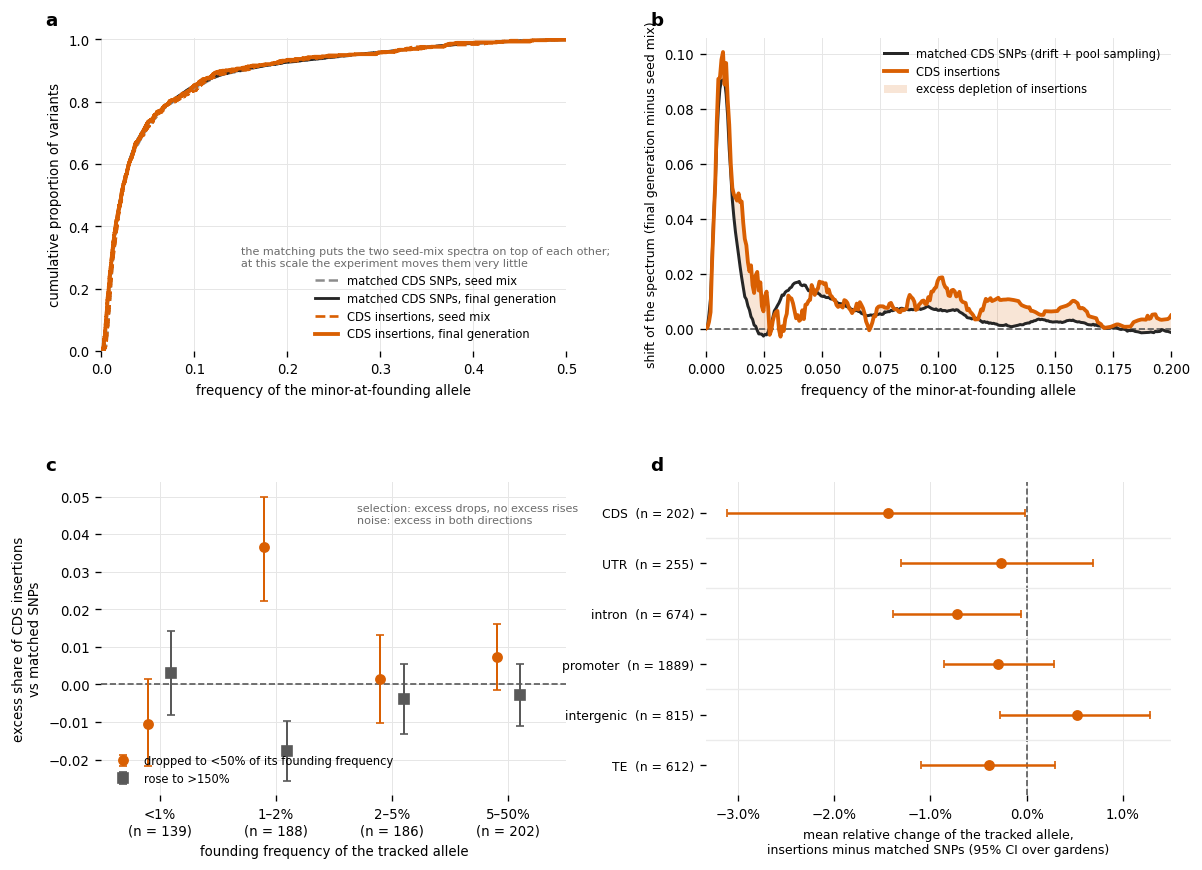

(a, b) share of the class below a frequency threshold, seed mix vs final generation:
 threshold  ins_seed  ins_final  ins_change  snp_seed  snp_final  snp_change  excess
      0.01    0.1944     0.2699      0.0755    0.1978     0.2637      0.0660  0.0095
      0.02    0.4573     0.4727      0.0154    0.4796     0.4830      0.0034  0.0120
      0.05    0.7175     0.7329      0.0154    0.7164     0.7281      0.0116  0.0038

(c) excess share of CDS insertions vs matched SNPs, by direction and founding frequency
    (excess_p0matched: SNPs additionally re-weighted to the insertions' p0 deciles):
direction   bin  n_ins  excess      lo      hi  gardens_pos  excess_p0matched   lo_p0   hi_p0
     drop   <1%    139 -0.0105 -0.0216  0.0015           11           -0.0072 -0.0179  0.0043
     drop  1–2%    188  0.0366  0.0222  0.0500           26            0.0375  0.0234  0.0508
     drop  2–5%    186  0.0014 -0.0102  0.0132           16           -0.0006 -0.0120  0.0111
     drop 5–50%    202  0

In [5]:

def tracked(idx):
    # the allele below 50% in the seed mix, at both timepoints: no polarity assumed, no reflection at 0.5
    p0=PV[idx,0]; pg=PV[idx,1:]; flip=p0>0.5
    return np.where(flip,1-p0,p0), np.where(flip[:,None],1-pg,pg)
def wecdf(a,v,w,**k):
    o=np.argsort(v); v=v[o]; c=np.cumsum(w[o])/w.sum(); a.step(np.r_[0,v],np.r_[0,c],where="post",**k)
def wecdf_at(v,w,x):
    o=np.argsort(v); vs=v[o]; c=np.cumsum(w[o])/w.sum(); return np.interp(x,vs,c,left=0,right=1)
def wshare(v,w,lo=None,hi=None):
    m=np.isfinite(v)
    if lo is not None: m&=v<lo
    if hi is not None: m&=v>hi
    return w[m].sum()/w.sum()
def p0_reweight(pi,ps,ws,nq=10):
    # founding-frequency matching on top of the carrier-count matching: SNPs re-weighted to the events' p0 deciles
    qs=np.quantile(pi,np.linspace(0,1,nq+1)); qs[0]=-np.inf; qs[-1]=np.inf
    bi=np.digitize(pi,qs[1:-1]); bs=np.digitize(ps,qs[1:-1]); w2=np.zeros(ps.size)
    for d in range(nq):
        tgt=(bi==d).sum(); pool=bs==d
        if tgt and ws[pool].sum()>0: w2[pool]+=ws[pool]*tgt/ws[pool].sum()
    return w2
ci0=CTX.index("CDS"); ms=(KD=="ins")&(CX==ci0); mn=(KD=="snp")&(CX==ci0)
si,w,_=matched_snps(ms,mn); p0i,pgi=tracked(np.where(ms)[0]); p0s,pgs=tracked(si)
wi=np.ones(p0i.size); pfi=pgi.mean(1); pfs=pgs.mean(1)
fig=plt.figure(figsize=(11.5,8.2)); gs_=fig.add_gridspec(2,2,wspace=0.30,hspace=0.42)
# (a) both spectra, seed mix and final generation
a=fig.add_subplot(gs_[0,0]); style(a); panel(a,"a")
for v,ww,col,ls,lw,lab in ((p0s,w,"0.55","--",1.5,"matched CDS SNPs, seed mix"),(pfs,w,"0.15","-",1.7,"matched CDS SNPs, final generation"),
                           (p0i,wi,KC["ins"],"--",1.6,"CDS insertions, seed mix"),(pfi,wi,KC["ins"],"-",2.3,"CDS insertions, final generation")):
    wecdf(a,v,ww,color=col,ls=ls,lw=lw,label=lab)
a.set_xlim(0,0.5); a.set_ylim(0,1.005); a.set_xlabel("frequency of the minor-at-founding allele")
a.set_ylabel("cumulative proportion of variants"); a.legend(frameon=False,fontsize=6.9,loc="lower right")
a.annotate("the matching puts the two seed-mix spectra on top of each other;\nat this scale the experiment moves them very little",
           xy=(0.30,0.27),xycoords="axes fraction",fontsize=6.7,color="0.42")
# (b) the same as a residual: cumulative share at the final generation minus at the seed mix
a=fig.add_subplot(gs_[0,1]); style(a); panel(a,"b"); a.axhline(0,color="0.35",lw=1,ls="--")
xg=np.linspace(0,0.2,300); dS=wecdf_at(pfs,w,xg)-wecdf_at(p0s,w,xg); dI=wecdf_at(pfi,wi,xg)-wecdf_at(p0i,wi,xg)
a.plot(xg,dS,color="0.15",lw=1.8,label="matched CDS SNPs (drift + pool sampling)")
a.plot(xg,dI,color=KC["ins"],lw=2.3,label="CDS insertions")
a.fill_between(xg,dS,dI,where=dI>=dS,color=KC["ins"],alpha=0.16,lw=0,label="excess depletion of insertions")
a.set_xlim(0,0.2); a.set_xlabel("frequency of the minor-at-founding allele")
a.set_ylabel("shift of the spectrum (final generation minus seed mix)",fontsize=7.5)
a.legend(frameon=False,fontsize=6.9,loc="upper right")
# (c) the separation decomposed: direction x founding frequency
a=fig.add_subplot(gs_[1,0]); style(a); panel(a,"c"); a.axhline(0,color="0.35",lw=1,ls="--")
EDG=[0,0.01,0.02,0.05,0.5]; LBL=["<1%","1–2%","2–5%","5–50%"]; ri=pgi/p0i[:,None]; rs=pgs/p0s[:,None]; SFSB=[]
for sgn,col,mk,lab in (("drop",KC["ins"],"o","dropped to <50% of its founding frequency"),("rise","0.35","s","rose to >150%")):
    xs=[];ys=[];los=[];his=[]
    for b in range(len(EDG)-1):
        bmi=(p0i>=EDG[b])&(p0i<EDG[b+1]); bms=(p0s>=EDG[b])&(p0s<EDG[b+1])
        if bmi.sum()<20: continue
        w2=p0_reweight(p0i[bmi],p0s[bms],w[bms]); kw=dict(lo=0.5) if sgn=="drop" else dict(hi=1.5)
        d=np.array([wshare(ri[bmi,g],wi[bmi],**kw)-wshare(rs[bms,g],w[bms],**kw) for g in range(31)])
        dp=np.array([wshare(ri[bmi,g],wi[bmi],**kw)-wshare(rs[bms,g],w2,**kw) for g in range(31)])
        lo,hi=bci(d); lp,hp=bci(dp)
        xs.append(b+(-0.1 if sgn=="drop" else 0.1)); ys.append(d.mean()); los.append(d.mean()-lo); his.append(hi-d.mean())
        SFSB.append(dict(direction=sgn,bin=LBL[b],n_ins=int(bmi.sum()),excess=d.mean(),lo=lo,hi=hi,
                         gardens_pos=int((d>0).sum()),excess_p0matched=dp.mean(),lo_p0=lp,hi_p0=hp))
    a.errorbar(xs,ys,yerr=[los,his],fmt=mk,color=col,ms=5.5,capsize=2.5,lw=0,elinewidth=1.2,label=lab)
a.set_xticks(range(len(LBL))); a.set_xticklabels([f"{l}\n(n = {int(((p0i>=EDG[i])&(p0i<EDG[i+1])).sum())})" for i,l in enumerate(LBL)])
a.set_xlim(-0.5,len(LBL)-0.5); a.set_xlabel("founding frequency of the tracked allele")
a.set_ylabel("excess share of CDS insertions\nvs matched SNPs")
a.legend(frameon=False,fontsize=6.9,loc="lower left")
a.annotate("selection: excess drops, no excess rises\nnoise: excess in both directions",
           xy=(0.55,0.87),xycoords="axes fraction",fontsize=6.7,color="0.42")
# (d) per context, variants starting at >= 5%
a=fig.add_subplot(gs_[1,1]); style(a,axis="x"); panel(a,"d"); a.axvline(0,color="0.35",lw=1,ls="--")
order=["TE","intergenic","promoter","intron","UTR","CDS"]; FOLD0=np.minimum(PV[:,0],1-PV[:,0]); SFSC=[]; ylab=[]
for yi,ctx in enumerate(order):
    cc=CTX.index(ctx); m1=(KD=="ins")&(CX==cc)&(FOLD0>=0.05); m2=(KD=="snp")&(CX==cc)&(FOLD0>=0.05)
    s2,w2,_=matched_snps(m1,m2); q0i,qgi=tracked(np.where(m1)[0]); q0s,qgs=tracked(s2)
    w3=p0_reweight(q0i,q0s,w2)
    d=np.array([(qgi[:,g]/q0i-1).mean()-((qgs[:,g]/q0s-1)*w2).sum()/w2.sum() for g in range(31)])
    dp=np.array([(qgi[:,g]/q0i-1).mean()-((qgs[:,g]/q0s-1)*w3).sum()/w3.sum() for g in range(31)])
    lo,hi=bci(d); lp,hp=bci(dp)
    a.errorbar(d.mean(),yi,xerr=[[d.mean()-lo],[hi-d.mean()]],fmt="o",color=KC["ins"],ms=5.5,capsize=2.5,zorder=3)
    ylab.append(f"{ctx}  (n = {int(m1.sum())})")
    SFSC.append(dict(context=ctx,n_ins=int(m1.sum()),mean=d.mean(),lo=lo,hi=hi,gardens_neg=int((d<0).sum()),
                     mean_p0matched=dp.mean(),lo_p0=lp,hi_p0=hp))
    if yi<5: a.axhline(yi+0.5,color="0.92",lw=0.8)
a.set_yticks(range(6)); a.set_yticklabels(ylab,fontsize=7.4); a.set_ylim(-0.6,5.6)
a.set_xlabel("mean relative change of the tracked allele,\ninsertions minus matched SNPs (95% CI over gardens)",fontsize=7.5)
a.xaxis.set_major_formatter(PercentFormatter(1.0,decimals=1))
fig.savefig(f"{G}/plots/sfs_seedmix_vs_final.png",dpi=200,bbox_inches="tight")
fig.savefig(f"{G}/plots/sfs_seedmix_vs_final.pdf",bbox_inches="tight"); plt.show()
SFSA=[dict(threshold=t,ins_seed=wshare(p0i,wi,lo=t),ins_final=wshare(pfi,wi,lo=t),snp_seed=wshare(p0s,w,lo=t),snp_final=wshare(pfs,w,lo=t)) for t in (0.01,0.02,0.05)]
for r_ in SFSA: r_["ins_change"]=r_["ins_final"]-r_["ins_seed"]; r_["snp_change"]=r_["snp_final"]-r_["snp_seed"]; r_["excess"]=r_["ins_change"]-r_["snp_change"]
print("(a, b) share of the class below a frequency threshold, seed mix vs final generation:")
print(pd.DataFrame(SFSA)[["threshold","ins_seed","ins_final","ins_change","snp_seed","snp_final","snp_change","excess"]].round(4).to_string(index=False))
print("\n(c) excess share of CDS insertions vs matched SNPs, by direction and founding frequency")
print("    (excess_p0matched: SNPs additionally re-weighted to the insertions' p0 deciles):")
print(pd.DataFrame(SFSB).round(4).to_string(index=False))
print("\n(d) mean relative change of the tracked allele, insertions minus matched SNPs, founding frequency >= 5%:")
print(pd.DataFrame(SFSC).round(4).to_string(index=False))


#### One garden at a time

The spectra above use each event's frequency averaged over the 31 gardens, which suppresses
per-garden noise by roughly √31 but also averages away anything garden-specific. Here the same
spectra are drawn one garden at a time: **(a)** site 4 and **(b)** site 32, plus **(c)** site 24,
the coldest garden, as a contrast. **(d)** the per-garden statistic for all 31 gardens against
garden temperature.

**Read (a)–(c) with the matched-SNP curve, not the insertion curve.** Averaging over gardens is what
kept panel (a) of the previous figure nearly still; in a single garden the whole spectrum collapses
toward rare — the share of CDS insertions below 1% goes from 0.19 in the seed mix to 0.49 in site 4
and 0.52 in site 32. Almost none of that is selection: the matched SNPs move the same distance in the
same gardens (0.48 and 0.52 respectively). A single garden's spectrum is one noisy realisation — pool
sampling, drift in a small plot, and kMate estimation error all land on it — so the only interpretable
quantity remains the gap between the insertion and matched-SNP curves.

*Statistics.* Per garden there is no bootstrap over gardens to take, so the intervals here are a
bootstrap over **events** (2,000 resamples of the insertions, and of the weighted matched-SNP set);
the inference target is therefore "within this garden, do insertions differ from their matched SNPs?",
not "does this generalise across gardens". The statistic is the one from panel (d) of the previous
figure: the insertions' mean relative change of the tracked allele minus the matched SNPs' weighted
mean, restricted to variants starting at ≥ 5%.

**What the named sites do.** Site 4 is the most extreme garden in the whole panel (−17.6%, rank 1 of
31), but on 202 events in one garden the event-bootstrap interval is [−37.3, +3.7] and includes zero,
so on its own it is suggestive rather than conclusive. Site 32, despite also being a hot garden, is
unremarkable on this statistic (−0.5%, rank 17 of 31) — whatever makes it a strong-selection site does
not show up as excess purging of CDS insertions. The structure is in (d) rather than in any single
garden: the excess decline of insertions is stronger in warmer gardens, and is near zero or slightly
positive in the cold ones. That gradient is already part of this figure's established result — Figure 2c
reports the same slope on the load statistic (−0.0016/°C, p = 0.022) — and by the criterion stated
there, a slope on temperature is the signature of lineage sorting rather than of uniform purifying
selection, so it should not be read as strengthening the CDS-purging claim.

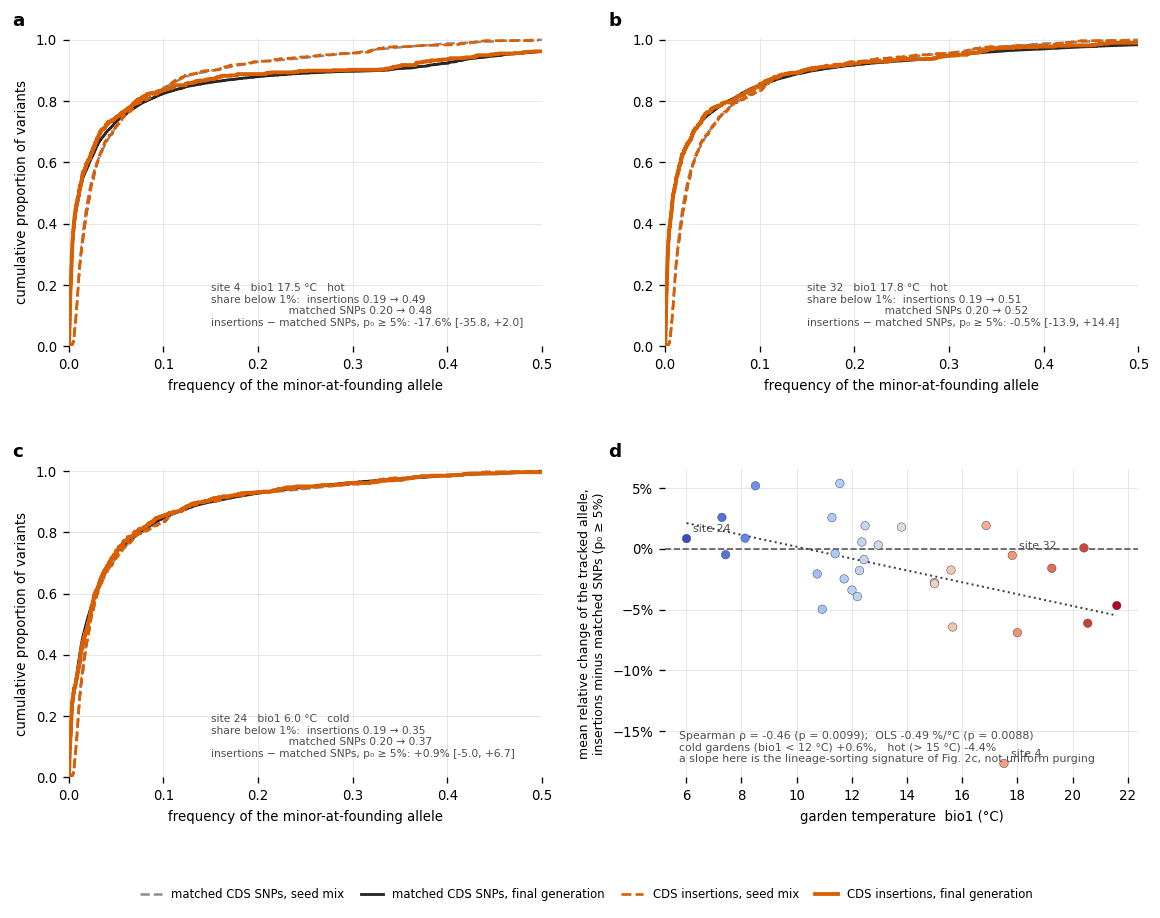

highlighted gardens (intervals are a bootstrap over EVENTS, 2,000 resamples, not over gardens):
 site    bio1 zone  ins_lt1_seed  ins_lt1_final  snp_lt1_seed  snp_lt1_final  relch_p0ge5  event_boot_lo  event_boot_hi
    4 17.5135  hot        0.1944         0.4867        0.1978         0.4771      -0.1764        -0.3580         0.0204
   32 17.8152  hot        0.1944         0.5147        0.1978         0.5197      -0.0053        -0.1391         0.1438
   24  6.0089 cold        0.1944         0.3524        0.1978         0.3693       0.0085        -0.0498         0.0672

all 31 gardens, sorted by temperature (rank 1 = strongest excess decline of insertions):
 site    bio1 zone  relch_p0ge5  relch_all  ins_lt1_final  snp_lt1_final  rank_relch
   24  6.0089 cold       0.0085    -0.0158         0.3524         0.3693          23
   23  7.2909 cold       0.0259     0.0099         0.2825         0.2742          29
   27  7.4251 cold      -0.0048     0.0331         0.5063         0.5131       

In [6]:

SITE=GS["sites"]; ZN_=GS["zone"].astype(str)
SEL=[4,32,24]                                          # sites 4 and 32, plus the coldest garden as a contrast
gidx={int(s):int(np.where(SITE==s)[0][0]) for s in SEL}
g5i=p0i>=0.05; g5s=p0s>=0.05
def relch(g):
    return (pgi[g5i,g]/p0i[g5i]-1).mean()-((pgs[g5s,g]/p0s[g5s]-1)*w[g5s]).sum()/w[g5s].sum()
rngG=np.random.default_rng(7)
def relch_boot(g,B=2000):
    out=np.empty(B)
    for t in range(B):
        a_=rngG.integers(0,p0i.size,p0i.size); b_=rngG.integers(0,p0s.size,p0s.size)
        ai=a_[p0i[a_]>=0.05]; bi=b_[p0s[b_]>=0.05]
        out[t]=(pgi[ai,g]/p0i[ai]-1).mean()-((pgs[bi,g]/p0s[bi]-1)*w[bi]).sum()/w[bi].sum()
    return np.percentile(out,[2.5,97.5])
fig=plt.figure(figsize=(11.5,8.0)); gs_=fig.add_gridspec(2,2,wspace=0.26,hspace=0.40); SFSG=[]
for k_,s_ in enumerate(SEL):
    g=gidx[s_]; a=fig.add_subplot(gs_[k_//2,k_%2]); style(a); panel(a,"abc"[k_])
    for v,ww,col,ls,lw,lab in ((p0s,w,"0.55","--",1.5,"matched CDS SNPs, seed mix"),(pgs[:,g],w,"0.15","-",1.7,"matched CDS SNPs, final generation"),
                               (p0i,wi,KC["ins"],"--",1.6,"CDS insertions, seed mix"),(pgi[:,g],wi,KC["ins"],"-",2.3,"CDS insertions, final generation")):
        wecdf(a,v,ww,color=col,ls=ls,lw=lw,label=lab)
    a.set_xlim(0,0.5); a.set_ylim(0,1.005); a.set_xlabel("frequency of the minor-at-founding allele")
    if k_%2==0: a.set_ylabel("cumulative proportion of variants")
    lo,hi=relch_boot(g); r5=relch(g)
    SFSG.append(dict(site=s_,bio1=BIO[g],zone=ZN_[g],ins_lt1_seed=wshare(p0i,wi,lo=0.01),ins_lt1_final=wshare(pgi[:,g],wi,lo=0.01),
                     snp_lt1_seed=wshare(p0s,w,lo=0.01),snp_lt1_final=wshare(pgs[:,g],w,lo=0.01),relch_p0ge5=r5,event_boot_lo=lo,event_boot_hi=hi))
    a.annotate(f"site {s_}   bio1 {BIO[g]:.1f} °C   {ZN_[g]}\nshare below 1%:  insertions {wshare(p0i,wi,lo=0.01):.2f} → {wshare(pgi[:,g],wi,lo=0.01):.2f}\n"
               f"                       matched SNPs {wshare(p0s,w,lo=0.01):.2f} → {wshare(pgs[:,g],w,lo=0.01):.2f}\n"
               f"insertions − matched SNPs, p₀ ≥ 5%: {100*r5:+.1f}% [{100*lo:+.1f}, {100*hi:+.1f}]",
               xy=(0.30,0.06),xycoords="axes fraction",ha="left",va="bottom",fontsize=6.4,color="0.3")
    if k_==0: h_,l_=a.get_legend_handles_labels()
# (d) all 31 gardens against garden temperature
a=fig.add_subplot(gs_[1,1]); style(a); panel(a,"d"); a.axhline(0,color="0.35",lw=1,ls="--")
RC=np.array([relch(g) for g in range(31)])
a.scatter(BIO,RC,c=BIO,cmap="coolwarm",vmin=BIO.min(),vmax=BIO.max(),s=26,linewidth=0.3,edgecolor="0.3",zorder=3)
lr=stats.linregress(BIO,RC); xx=np.linspace(BIO.min(),BIO.max(),50); a.plot(xx,lr.intercept+lr.slope*xx,color="0.25",lw=1.2,ls=":")
rho,prho=stats.spearmanr(BIO,RC)
for s_ in SEL:
    g=gidx[s_]; a.annotate(f"site {s_}",xy=(BIO[g],RC[g]),xytext=(4,4),textcoords="offset points",fontsize=6.6,color="0.3")
a.set_xlabel("garden temperature  bio1 (°C)")
a.set_ylabel("mean relative change of the tracked allele,\ninsertions minus matched SNPs (p₀ ≥ 5%)",fontsize=7.5)
a.yaxis.set_major_formatter(PercentFormatter(1.0,decimals=0))
a.annotate(f"Spearman ρ = {rho:+.2f} (p = {prho:.2g});  OLS {100*lr.slope:+.2f} %/°C (p = {lr.pvalue:.2g})\n"
           f"cold gardens (bio1 < 12 °C) {100*RC[BIO<12].mean():+.1f}%,   hot (> 15 °C) {100*RC[BIO>15].mean():+.1f}%\n"
           f"a slope here is the lineage-sorting signature of Fig. 2c, not uniform purging",
           xy=(0.03,0.05),xycoords="axes fraction",fontsize=6.6,color="0.3")
fig.legend(h_,l_,frameon=False,fontsize=7,loc="lower center",bbox_to_anchor=(0.5,-0.03),ncol=4,columnspacing=1.4,handlelength=1.9)
fig.savefig(f"{G}/plots/sfs_per_garden.png",dpi=200,bbox_inches="tight")
fig.savefig(f"{G}/plots/sfs_per_garden.pdf",bbox_inches="tight"); plt.show()
print("highlighted gardens (intervals are a bootstrap over EVENTS, 2,000 resamples, not over gardens):")
print(pd.DataFrame(SFSG).round(4).to_string(index=False))
ALLG=pd.DataFrame(dict(site=SITE,bio1=BIO,zone=ZN_,relch_p0ge5=RC,
                       relch_all=[(pgi[:,g]/p0i-1).mean()-((pgs[:,g]/p0s-1)*w).sum()/w.sum() for g in range(31)],
                       ins_lt1_final=[wshare(pgi[:,g],wi,lo=0.01) for g in range(31)],
                       snp_lt1_final=[wshare(pgs[:,g],w,lo=0.01) for g in range(31)]))
ALLG["rank_relch"]=ALLG.relch_p0ge5.rank().astype(int)
print("\nall 31 gardens, sorted by temperature (rank 1 = strongest excess decline of insertions):")
print(ALLG.round(4).to_string(index=False))
r2,p2=stats.spearmanr(ALLG.bio1,ALLG.relch_all)
print(f"\nclimate gradient: p0 >= 5% statistic Spearman rho = {rho:+.3f} (p = {prho:.3g});  all-event statistic rho = {r2:+.3f} (p = {p2:.3g})")
print("the all-event version is a mean of ratios, dominated by the rarest events; the p0 >= 5% version is the one plotted.")
print(f"for comparison, Figure 2c's load statistic on the same gardens: slope {stats.linregress(BIO,load_diff((KD=='ins')&(CX==ci0),(KD=='snp')&(CX==ci0))).slope:+.4f}/°C")
